# **Pós-Graduação em Data Science and Digital Transformation**
## *Análise de Dados e Aprendizagem Automática*

---

# **Trabalho Prático 2 — Previsão da Situação Académica de Estudantes do IPP**

### Ana Estreia

O objetivo deste trabalho é treinar modelos de aprendizagem máquina para prever, com base em informação recolhida no momento da matrícula, se um estudante de Licenciatura do Instituto Politécnico de Portalegre (IPP) irá ou não obter o seu diploma ao fim de N anos de frequência.

A variável alvo é Categoria que pode tomar os valores Diplomado ou Não Diplomado.


# 1. Importação de Bibliotecas


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import confusion_matrix, classification_report, f1_score, accuracy_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, OrdinalEncoder, RobustScaler



# 2. Carregamento dos Dados


In [ ]:
dados = pd.read_excel("dataset_PIAES_reduced.xlsx")
dados.head()


,Sexo (M/F),Estado civil (desc),Ordem de ingresso,Curso (desc),Deslocado (S/N),Nacionalidade (desc),Habilitação literária mãe (desc),Situação profissional mãe (desc),Situação profissional pai (desc),Nota ingresso,Bolseiro,Idade no ingresso,Categoria
0,M,Solteiro(a),5,Design de Animação e Multimédia,S,Portuguesa,Outro - 11º Ano de Escolaridade,Trabalhador(a) por Conta de Outrém,Outra Situação (Falecido/a),127.3,0,20.0,Não Diplomado
1,M,Solteiro(a),1,Turismo,S,Portuguesa,Ensino Superior - Licenciatura,Trabalhador(a) por Conta de Outrém,Trabalhador(a) por Conta de Outrém,142.5,0,19.0,Diplomado
2,M,Solteiro(a),5,Design de Comunicação,S,Portuguesa,Ensino Básico 1º Ciclo (4º/5º Ano) ou Equiv.,Trabalhador(a) por Conta de Outrém,Desempregado/a,124.8,0,19.0,Não Diplomado
3,F,Solteiro(a),2,Jornalismo e Comunicação,S,Portuguesa,Ensino Básico 1º Ciclo (4º/5º Ano) ou Equiv.,Trabalhador(a) por Conta de Outrém,Trabalhador(a) por Conta de Outrém,119.6,0,20.0,Diplomado
4,F,Casado(a) com registo,1,Serviço Social (pós-laboral),N,Portuguesa,Ensino Básico 2º Ciclo (6º/7º/8º Ano) ou Equiv.,Reformado/a,Reformado/a,141.5,0,45.0,Diplomado


In [ ]:
dados.shape


(5742, 13)

In [ ]:
dados.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5742 entries, 0 to 5741
Data columns (total 13 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Sexo (M/F)                        5742 non-null   object 
 1   Estado civil (desc)               5742 non-null   object 
 2   Ordem de ingresso                 5742 non-null   int64  
 3   Curso (desc)                      5742 non-null   object 
 4   Deslocado (S/N)                   5742 non-null   object 
 5   Nacionalidade (desc)              5742 non-null   object 
 6   Habilitação literária mãe (desc)  5722 non-null   object 
 7   Situação profissional mãe (desc)  5742 non-null   object 
 8   Situação profissional pai (desc)  5742 non-null   object 
 9   Nota ingresso                     5674 non-null   float64
 10  Bolseiro                          5742 non-null   int64  
 11  Idade no ingresso                 5691 non-null   float64
 12  Catego

In [ ]:
dados.describe()


,Ordem de ingresso,Nota ingresso,Bolseiro,Idade no ingresso
count,5742.000000,5674.000000,5742.000000,5691.000000
mean,1.730059,126.764406,0.228144,23.194166
std,1.314212,14.679133,0.419672,7.313257
min,0.000000,45.200000,0.000000,17.000000
25%,1.000000,117.400000,0.000000,19.000000
50%,1.000000,125.700000,0.000000,20.000000
75%,2.000000,134.800000,0.000000,25.000000
max,9.000000,190.000000,1.000000,61.000000


# 3. Análise Exploratória dos Dados


## 3.1 Variável Alvo


In [ ]:
# valores de cada classe
dados["Categoria"].value_counts()

,count
Categoria,
Não Diplomado,3264
Diplomado,2478


In [ ]:
# percentagem de cada classe
dados['Categoria'].value_counts(normalize=True) * 100

,proportion
Categoria,
Não Diplomado,56.844305
Diplomado,43.155695


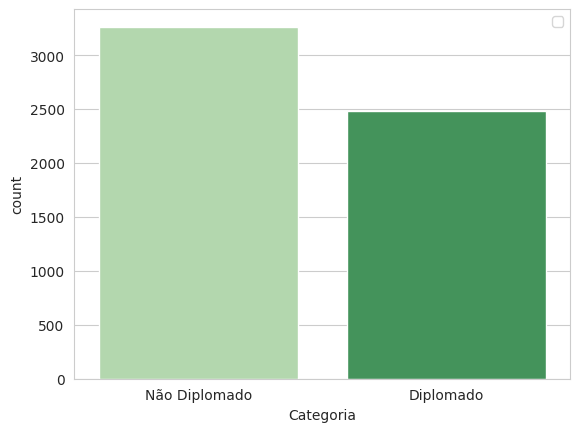

In [ ]:
# distribuição da variável alvo
sns.countplot(x="Categoria", data=dados, palette="Greens")
plt.legend(loc='upper right')

plt.show()


## 3.2 Correlação entre variáveis numéricas


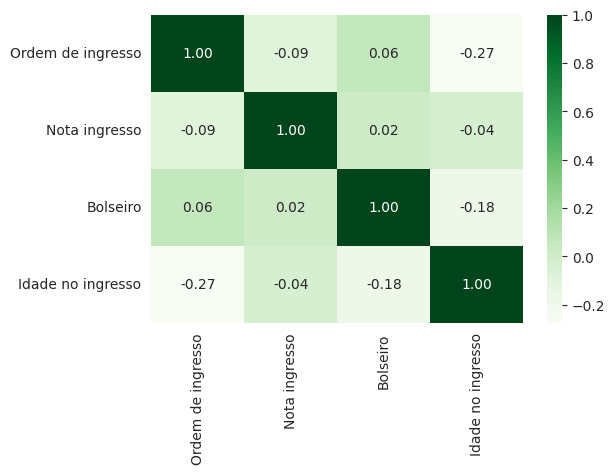

In [ ]:
dados_num = dados.select_dtypes(include="number")
plt.figure(figsize=(6,4))
sns.heatmap(dados_num.corr(), annot=True, cmap="Greens", fmt=".2f")

plt.show()


As variáveis numéricas não estão correlacionadas entre si, sendo portanto adequadas para serem usadas como variáveis independentes na criação de um modelo de regressão logística

# 4. Pré-processamento

Antes de qualquer transformação, separa-se os dados em treino e teste para evitar o vazamento de dados (*data leakage*).


## 4.1 Separação Treino/Teste


In [ ]:
# Separar variável alvo das restantes
y = dados["Categoria"]
X = dados.drop("Categoria", axis=1)

# Split 80/20
Xtrain, Xtest, ytrain, ytest = train_test_split(
    X, y, train_size=0.8, test_size=0.2, random_state=0,
)

print(f"Treino: {Xtrain.shape}")
print(f"Teste:  {Xtest.shape}")

Treino: (4593, 12)
Teste:  (1149, 12)


## 4.2 Valores Ausentes


In [ ]:
# Verificar valores ausentes no conjunto de treino
ausentes = Xtrain.isna().sum()
ausentes_pct = Xtrain.isna().sum() / len(Xtrain) * 100

pd.DataFrame({"Ausentes": ausentes, "Percentagem (%)": ausentes_pct.round(1)}).sort_values("Ausentes", ascending=False)


,Ausentes,Percentagem (%)
Nota ingresso,52,1.1
Idade no ingresso,42,0.9
Habilitação literária mãe (desc),17,0.4
Sexo (M/F),0,0.0
Curso (desc),0,0.0
Ordem de ingresso,0,0.0
Estado civil (desc),0,0.0
Deslocado (S/N),0,0.0
Situação profissional mãe (desc),0,0.0
Nacionalidade (desc),0,0.0


### 4.2.1 Atributos numéricos

In [ ]:
#Seleção dos atributos numéricos
Xtrain_numeric = Xtrain.select_dtypes(include='number')
Xtest_numeric = Xtest.select_dtypes(include='number')

In [ ]:
# Imputar valores numéricos com mediana[, melhor face a outliers]
my_imputer = SimpleImputer(strategy='median')

Xtrain_num_imp = pd.DataFrame(my_imputer.fit_transform(Xtrain_numeric),
                              index= Xtrain_numeric.index,
                              columns=Xtrain_numeric.columns)
# transform() para os dados de teste, para evitar vazamento de dados
Xtest_num_imp = pd.DataFrame(my_imputer.transform(Xtest_numeric),
                             index= Xtest_numeric.index,
                              columns=Xtest_numeric.columns)


# Confirmar que não há mais ausentes
print("TRAIN: ")
print(Xtrain_num_imp.isna().sum())
print("\nTEST:");
print(Xtest_num_imp.isna().sum())

TRAIN: 
Ordem de ingresso    0
Nota ingresso        0
Bolseiro             0
Idade no ingresso    0
dtype: int64

TEST:
Ordem de ingresso    0
Nota ingresso        0
Bolseiro             0
Idade no ingresso    0
dtype: int64


### 4.2.2 Atributos categóricos

In [ ]:
#Seleção dos atributos categóricos
Xtrain_cat = Xtrain.select_dtypes(include ='object')
Xtest_cat = Xtest.select_dtypes(include ='object')

In [ ]:
# Imputar valores categóricos valor mais frequente
my_imputer_mf = SimpleImputer(strategy='most_frequent')

#usar o imputer separadamente no treino e teste.
#converter em DataFrame, já com o nome das colunas
Xtrain_cat_imputed = pd.DataFrame(my_imputer_mf.fit_transform(Xtrain_cat),
                                  index = Xtrain_cat.index,
                                  columns=Xtrain_cat.columns)
Xtest_cat_imputed = pd.DataFrame(my_imputer_mf.transform(Xtest_cat),
                                 index = Xtest_cat.index,
                                 columns=Xtest_cat.columns)

# Confirmar que não há mais ausentes
print("TRAIN: ")
print(Xtrain_cat_imputed.isna().sum())
print("\nTEST: ")
print(Xtest_cat_imputed.isna().sum())


TRAIN: 
Sexo (M/F)                          0
Estado civil (desc)                 0
Curso (desc)                        0
Deslocado (S/N)                     0
Nacionalidade (desc)                0
Habilitação literária mãe (desc)    0
Situação profissional mãe (desc)    0
Situação profissional pai (desc)    0
dtype: int64

TEST: 
Sexo (M/F)                          0
Estado civil (desc)                 0
Curso (desc)                        0
Deslocado (S/N)                     0
Nacionalidade (desc)                0
Habilitação literária mãe (desc)    0
Situação profissional mãe (desc)    0
Situação profissional pai (desc)    0
dtype: int64


## 4.3 Transformar Variáveis Categóricas


###4.3.1 OneHotEncoder - variáveis de baixa cardinalidade

In [ ]:
cardinalidade_cat = pd.DataFrame({
    'Cardinalidade': Xtrain_cat_imputed.nunique()
})
cardinalidade_cat.sort_values('Cardinalidade')

,Cardinalidade
Sexo (M/F),2
Deslocado (S/N),2
Estado civil (desc),6
Situação profissional pai (desc),10
Situação profissional mãe (desc),10
Curso (desc),17
Nacionalidade (desc),22
Habilitação literária mãe (desc),33


As colunas `Sexo (M/F)` e `Deslocado (S/N)` podem ser facilmente codificadas em variáveis numéricas, porque a sua cardinalidade é baixa (2). Para tal, será usado o **OneHotEncoder**

In [ ]:
ohe = OneHotEncoder(sparse_output=False, drop='first')


In [ ]:
# nome das colunas a ser adicionadas
colunas=["Sexo", "Deslocado"]
# aplicar o One-Hot Encoder ao treino e teste
Xtrain_cat_ohe = pd.DataFrame(ohe.fit_transform(Xtrain_cat_imputed[['Sexo (M/F)', 'Deslocado (S/N)']]),
                              columns = colunas,
                              index = Xtrain_cat_imputed.index)

Xtest_cat_ohe = pd.DataFrame(ohe.transform(Xtest_cat_imputed[['Sexo (M/F)', 'Deslocado (S/N)']]),
                              columns = colunas,
                              index = Xtest_cat_imputed.index)

In [ ]:
Xtrain_cat_imputed[['Sexo (M/F)', 'Deslocado (S/N)']].head()

,Sexo (M/F),Deslocado (S/N)
5013,M,S
3370,F,S
242,F,N
2124,F,S
2749,F,S


In [ ]:
Xtrain_cat_ohe.head()

,Sexo,Deslocado
5013,1.0,1.0
3370,0.0,1.0
242,0.0,0.0
2124,0.0,1.0
2749,0.0,1.0


Comparando as respetivas colunas de Xtrain antes e depois da aplicação do OneHotEncoder, verifica-se:
* relativamente a *Sexo*:  `M` foi codificado com `1`, `F` com `0`.
* relativamente a *Deslocado*: `S` foi codificado com `1`, e `N` foi codificado com `0`.

In [ ]:
# juntar as colunas de dados numéricos às colunas de dados categóricos convertidos
Xtrain_encoded = Xtrain_num_imp.join(Xtrain_cat_ohe)
Xtest_encoded = Xtest_num_imp.join(Xtest_cat_ohe)

In [ ]:
print(Xtrain_encoded.shape)
print(Xtest_encoded.shape)

(4593, 6)
(1149, 6)


In [ ]:
Xtrain_encoded.head()

,Ordem de ingresso,Nota ingresso,Bolseiro,Idade no ingresso,Sexo,Deslocado
5013,3.0,113.0,0.0,19.0,1.0,1.0
3370,3.0,121.2,0.0,18.0,0.0,1.0
242,1.0,140.0,0.0,33.0,0.0,0.0
2124,5.0,127.6,0.0,18.0,0.0,1.0
2749,2.0,111.3,0.0,20.0,0.0,1.0


### 4.3.2 Habilitação Literária da Mãe — Codificação Ordinal

Esta variável tem 34 valores distintos, mas representam níveis de escolaridade com uma ordem natural implícita (e.g. Doutoramento > Licenciatura > Ensino Básico). Faz sentido usar uma codificação ordinal em vez de LabelEncoder, para que o modelo possa tirar partido dessa relação de ordem.

O valor "Desconhecido" é tratado como ausente e substituído pela mediana após o mapeamento.

In [ ]:
print(f"Número de valores únicos: {dados['Habilitação literária mãe (desc)'].nunique()}")
print(f"Valores únicos: {dados['Habilitação literária mãe (desc)'].unique()}\n")

Número de valores únicos: 34
Valores únicos: ['Outro - 11º Ano de Escolaridade' 'Ensino Superior - Licenciatura'
 'Ensino Básico 1º Ciclo (4º/5º Ano) ou Equiv.'
 'Ensino Básico 2º Ciclo (6º/7º/8º Ano) ou Equiv.'
 'Ensino Secundário (12º Ano) ou Equiv.'
 'Ensino Básico 3º Ciclo (9º/10º/11º Ano) ou Equiv.' '7º Ano (Antigo)'
 'Ensino Superior - Doutoramento' 'Ensino Superior - Mestrado' nan
 'Ensino Superior - Bacharelato' 'Desconhecido'
 'Curso de Especialização Tecnológica'
 '12º Ano de Escolaridade - Não Concluído' 'Curso Geral de Comércio'
 'Sabe ler sem possuir o 4º ano de escolaridade'
 '2º Ano Curso Complementar Liceal' '7º Ano de Escolaridade'
 'Ensino Superior - Licenciatura (1º ciclo)'
 '11º Ano de Escolaridade - Não Concluído' '10º Ano de Escolaridade'
 'Curso Complementar Liceal' 'Não sabe ler nem escrever'
 'Curso de Estudos Superiores Especializados' 'Curso Técnico-Profissional'
 '9º Ano de Escolaridade - Não Concluído' '8º Ano de Escolaridade'
 'Ensino Superior - Mestrado (

In [ ]:
# mapear cada nível para o nr de anos de escolaridade equivalentes
ordem_escolaridade = {
    'Não sabe ler nem escrever': 0,
    'Sabe ler sem possuir o 4º ano de escolaridade': 2, # valor aproximado para literacia básica
    'Ensino Básico 1º Ciclo (4º/5º Ano) ou Equiv.': 4,
    'Ensino Básico 2º Ciclo (6º/7º/8º Ano) ou Equiv.':6,
    '7º Ano de Escolaridade':7,
    '8º Ano de Escolaridade':8,
    '9º Ano de Escolaridade - Não Concluído':8,
    'Ensino Básico 3º Ciclo (9º/10º/11º Ano) ou Equiv.':9,
    '2º Ano Curso Complementar Liceal': 9, # antigo 5º ano do liceu
    'Curso Geral de Comércio': 9,
    'Curso Geral de Administração e Comércio': 9,
    '10º Ano de Escolaridade': 10,
    '11º Ano de Escolaridade - Não Concluído': 10,
    'Curso Complementar Liceal - Não Concluído': 10,
    'Outro - 11º Ano de Escolaridade': 11,
    '12º Ano de Escolaridade - Não Concluído': 11,
    '7º Ano (Antigo)': 11, # último ano do antigo liceu correspondia a 4 anos de primária + 7 de liceu
    'Curso Complementar Liceal': 11,
    '2ª Ciclo do Curso Geral Liceal': 11,
    'Ensino Secundário (12º Ano) ou Equiv.': 12,
    'Curso Técnico-Profissional': 12,
    'Complementar de Contabilidade e Administração': 12,
    'Frequência do Ensino Superior': 13, # assumir pelo menos 1 ano concluído
    'Curso de Especialização Tecnológica': 13,
    'Curso Técnico Superior Profissional': 14,
    'Ensino Superior - Bacharelato': 15,
    'Ensino Superior - Licenciatura (1º ciclo)':15,
    'Ensino Superior - Licenciatura': 16,
    'Curso de Estudos Superiores Especializados': 16,
    'Ensino Superior - Mestrado (2º ciclo)': 17,
    'Ensino Superior - Mestrado': 18,
    'Ensino Superior - Doutoramento (3º ciclo)': 20,
    'Ensino Superior - Doutoramento': 21,
    'Desconhecido': np.nan,
}

In [ ]:
col_hab = "Habilitação literária mãe (desc)"

Xtrain_cat_imputed["Habilitação Mãe (ord)"] = Xtrain_cat_imputed[col_hab].map(ordem_escolaridade)
Xtest_cat_imputed["Habilitação Mãe (ord)"]  = Xtest_cat_imputed[col_hab].map(ordem_escolaridade)

print("Valores ausentes em Habilitação Mãe (ord) — treino:", Xtrain_cat_imputed["Habilitação Mãe (ord)"].isna().sum())



Valores ausentes em Habilitação Mãe (ord) — treino: 90


In [ ]:
# Imputar os NaN resultantes (valor "Desconhecido") com a mediana do treino
mediana_hab = Xtrain_cat_imputed["Habilitação Mãe (ord)"].median()
Xtrain_cat_imputed["Habilitação Mãe (ord)"] = Xtrain_cat_imputed["Habilitação Mãe (ord)"].fillna(mediana_hab)
Xtest_cat_imputed["Habilitação Mãe (ord)"]  = Xtest_cat_imputed["Habilitação Mãe (ord)"].fillna(mediana_hab)

print("Valores ausentes em Habilitação Mãe (ord) — treino:", Xtrain_cat_imputed["Habilitação Mãe (ord)"].isna().sum())
# Este `drop_duplicates()` é usado apenas para visualizar as combinações únicas
# das habilitações literárias e seus valores ordinais, facilitando a verificação do mapeamento.
Xtrain_cat_imputed[["Habilitação literária mãe (desc)", "Habilitação Mãe (ord)"]].drop_duplicates().sort_values("Habilitação Mãe (ord)")

Valores ausentes em Habilitação Mãe (ord) — treino: 0


,Habilitação literária mãe (desc),Habilitação Mãe (ord)
4283,Não sabe ler nem escrever,0.0
5485,Sabe ler sem possuir o 4º ano de escolaridade,2.0
2124,Ensino Básico 1º Ciclo (4º/5º Ano) ou Equiv.,4.0
5013,Ensino Básico 2º Ciclo (6º/7º/8º Ano) ou Equiv.,6.0
934,7º Ano de Escolaridade,7.0
5018,9º Ano de Escolaridade - Não Concluído,8.0
3816,8º Ano de Escolaridade,8.0
1427,Desconhecido,9.0
288,Curso Geral de Comércio,9.0
1755,Ensino Básico 3º Ciclo (9º/10º/11º Ano) ou Equiv.,9.0


In [ ]:
# juntar as a coluna Habilitação Mãe (ord)
Xtrain_encoded = Xtrain_encoded.join(Xtrain_cat_imputed[["Habilitação Mãe (ord)"]])
Xtest_encoded = Xtest_encoded.join(Xtest_cat_imputed[["Habilitação Mãe (ord)"]])

In [ ]:
print(Xtrain_encoded.shape)
print(Xtest_encoded.shape)

(4593, 7)
(1149, 7)


In [ ]:
Xtrain_encoded.head()

,Ordem de ingresso,Nota ingresso,Bolseiro,Idade no ingresso,Sexo,Deslocado,Habilitação Mãe (ord)
5013,3.0,113.0,0.0,19.0,1.0,1.0,6.0
3370,3.0,121.2,0.0,18.0,0.0,1.0,6.0
242,1.0,140.0,0.0,33.0,0.0,0.0,12.0
2124,5.0,127.6,0.0,18.0,0.0,1.0,4.0
2749,2.0,111.3,0.0,20.0,0.0,1.0,6.0


### 4.3.3 OrdinalEncoder - Restantes Variáveis Categóricas

In [ ]:
cols_original = [
    "Estado civil (desc)",
    "Curso (desc)",
    "Nacionalidade (desc)",
    "Situação profissional mãe (desc)",
    "Situação profissional pai (desc)"
]

cols_new = [
    "Estado civil",
    "Curso",
    "Nacionalidade",
    "Situação profissional mãe",
    "Situação profissional pai"
]

# Configurar o OrdinalEncoder (alternativa ao label encoder para features)
# handle_unknown='use_encoded_value' evita o erro de "unseen labels"
# unknown_value=-1 atribui -1 a qualquer categoria nova que não estava no treino
ord_encoder = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

Xtrain_cat_ord_enc = pd.DataFrame(ord_encoder.fit_transform(Xtrain_cat_imputed[cols_original]),
                                  columns = cols_new,
                                  index = Xtrain_cat_imputed.index)

Xtest_cat_ord_enc = pd.DataFrame(ord_encoder.transform(Xtest_cat_imputed[cols_original]),
                                  columns = cols_new,
                                  index = Xtest_cat_imputed.index)

Para o tratamento das variáveis categóricas de elevada cardinalidade (como Curso e Nacionalidade), optou-se pela utilização do OrdinalEncoder em detrimento do LabelEncoder. Esta escolha justifica-se pela necessidade de robustez do modelo: ao configurar o parâmetro handle_unknown='use_encoded_value', garantimos que o modelo consiga processar categorias não observadas durante o treino (mapeando-as para o valor -1), evitando erros de execução.

In [ ]:
# juntar as colunas dos dados categóricos convertidos
Xtrain_encoded = Xtrain_encoded.join(Xtrain_cat_ord_enc)
Xtest_encoded = Xtest_encoded.join(Xtest_cat_ord_enc)

In [ ]:
print(Xtrain_encoded.shape)
print(Xtest_encoded.shape)

(4593, 12)
(1149, 12)


In [ ]:
Xtrain_encoded.head()

,Ordem de ingresso,Nota ingresso,Bolseiro,Idade no ingresso,Sexo,Deslocado,Habilitação Mãe (ord),Estado civil,Curso,Nacionalidade,Situação profissional mãe,Situação profissional pai
5013,3.0,113.0,0.0,19.0,1.0,1.0,6.0,4.0,12.0,15.0,3.0,9.0
3370,3.0,121.2,0.0,18.0,0.0,1.0,6.0,4.0,4.0,15.0,3.0,9.0
242,1.0,140.0,0.0,33.0,0.0,0.0,12.0,4.0,5.0,15.0,3.0,5.0
2124,5.0,127.6,0.0,18.0,0.0,1.0,4.0,4.0,5.0,15.0,9.0,9.0
2749,2.0,111.3,0.0,20.0,0.0,1.0,6.0,4.0,13.0,15.0,9.0,9.0


### 4.3.4 Transformar Variável Alvo


In [ ]:

ohe_y = OneHotEncoder(sparse_output=False, drop='first')
ytrain_enc = pd.Series(
    ohe_y.fit_transform(ytrain.values.reshape(-1, 1)).flatten(),
    index=ytrain.index,
    name=ytrain.name
)
ytest_enc = pd.Series(
    ohe_y.transform(ytest.values.reshape(-1, 1)).flatten(),
    index=ytest.index,
    name=ytest.name
)

# verificar correspondência
pd.DataFrame({'original': ytrain, 'codificado': ytrain_enc}).drop_duplicates()


,original,codificado
5013,Diplomado,0.0
3370,Não Diplomado,1.0


## 4.4 Padronização dos Dados

A padronização é necessária para algoritmos sensíveis à escala das variáveis, como o kNN, o SVM e as Redes Neuronais.

Sem padronização, variáveis com maior amplitude (ex.: Nota de ingresso, que varia entre 0 e 200) dominariam sobre variáveis com menor amplitude (ex.: Bolseiro, que toma apenas os valores 0 e 1), distorcendo os resultados.

Entre os scalers disponíveis, optou-se pelo RobustScaler pois este é robusto à presença de outliers. O StandardScaler e o MinMaxScaler seriam mais afetados por valores extremos, podendo distorcer a escala das restantes observações.


In [ ]:
cols_scl = ['Nota ingresso', 'Idade no ingresso', 'Ordem de ingresso',
    'Habilitação Mãe (ord)', 'Estado civil', 'Curso',
    'Nacionalidade', 'Situação profissional mãe', 'Situação profissional pai']

scaler = RobustScaler()

Xtrain_scl = Xtrain_encoded.copy()
Xtest_scl  = Xtest_encoded.copy()

Xtrain_scl[cols_scl] = scaler.fit_transform(Xtrain_encoded[cols_scl])
Xtest_scl[cols_scl]  = scaler.transform(Xtest_encoded[cols_scl])

Xtrain_scl.head()

,Ordem de ingresso,Nota ingresso,Bolseiro,Idade no ingresso,Sexo,Deslocado,Habilitação Mãe (ord),Estado civil,Curso,Nacionalidade,Situação profissional mãe,Situação profissional pai
5013,2.0,-0.769231,0.0,-0.166667,1.0,1.0,-0.375,0.0,0.625,0.0,-1.5,0.0
3370,2.0,-0.284024,0.0,-0.333333,0.0,1.0,-0.375,0.0,-0.375,0.0,-1.5,0.0
242,0.0,0.828402,0.0,2.166667,0.0,0.0,0.375,0.0,-0.250,0.0,-1.5,-1.0
2124,4.0,0.094675,0.0,-0.333333,0.0,1.0,-0.625,0.0,-0.250,0.0,0.0,0.0
2749,1.0,-0.869822,0.0,0.000000,0.0,1.0,-0.375,0.0,0.750,0.0,0.0,0.0


In [ ]:
Xtrain_scl.describe().round(2)


,Ordem de ingresso,Nota ingresso,Bolseiro,Idade no ingresso,Sexo,Deslocado,Habilitação Mãe (ord),Estado civil,Curso,Nacionalidade,Situação profissional mãe,Situação profissional pai
count,4593.00,4593.00,4593.00,4593.00,4593.00,4593.00,4593.00,4593.00,4593.00,4593.00,4593.00,4593.00
mean,0.74,0.05,0.23,0.53,0.37,0.52,-0.07,-0.43,0.06,-0.25,-0.52,-0.40
std,1.32,0.86,0.42,1.22,0.48,0.50,0.49,1.19,0.57,1.74,0.69,0.59
min,-1.00,-1.83,0.00,-0.50,0.00,0.00,-1.12,-4.00,-0.88,-15.00,-2.25,-2.25
25%,0.00,-0.49,0.00,-0.17,0.00,0.00,-0.62,0.00,-0.38,0.00,-1.00,-1.00
50%,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,1.00,0.51,0.00,0.83,1.00,1.00,0.38,0.00,0.62,0.00,0.00,0.00
max,8.00,3.79,1.00,6.67,1.00,1.00,1.50,1.00,1.12,6.00,0.00,0.00


O RobustScaler foi não aplicado às variáveis binárias (Sexo, Deslocado, Bolseiro) uma vez que estas já se encontram numa escala reduzida e padronizá-las não acrescentaria informação.

## 4.5 Dados desbalanceados

In [ ]:
print("\nDistribuição antes de SMOTE:")
print(ytrain_enc.value_counts())
print("\nDistribuição antes de SMOTE (%):")
print((ytrain_enc.value_counts(normalize=True) * 100).round(2))


Distribuição antes de SMOTE:
Categoria
1.0    2601
0.0    1992
Name: count, dtype: int64

Distribuição antes de SMOTE (%):
Categoria
1.0    56.63
0.0    43.37
Name: proportion, dtype: float64


In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(Xtrain_scl, ytrain_enc)

print("\nDistribuição após SMOTE:")
print(y_res.value_counts())
print("\nDistribuição após SMOTE (%):")
print((y_res.value_counts(normalize=True) * 100).round(2))


Distribuição após SMOTE:
Categoria
0.0    2601
1.0    2601
Name: count, dtype: int64

Distribuição após SMOTE (%):
Categoria
0.0    50.0
1.0    50.0
Name: proportion, dtype: float64


# 5. Função de Avaliação dos Modelos

Definimos uma função de avaliação comum a todos os modelos, igual à usada nas aulas.


In [ ]:
# DataFrame para registo de performance
performance = pd.DataFrame(columns=["Train Accuracy", "Test Accuracy", "Test f1"])


In [ ]:
rotulos = ["Diplomado", "Não Diplomado"]

def model_evaluation(acc_train, verdadeiros, previstos, titulo):
    """
    Imprime a matriz de confusão normalizada e o relatório de classificação.
    Regista a performance no DataFrame global.
    acc_train: accuracy do modelo no conjunto de treino
    verdadeiros: rótulos verdadeiros do conjunto de teste
    previstos: rótulos previstos pelo modelo no conjunto de teste
    titulo: título do modelo
    """
    conf_matrix = confusion_matrix(verdadeiros, previstos, normalize="true")
    s = sns.heatmap(conf_matrix, annot=True, cmap="Greens",
                    xticklabels=rotulos, yticklabels=rotulos, fmt=".2f")
    s.set(xlabel="Rótulo Previsto", ylabel="Rótulo Verdadeiro", title=titulo)
    plt.show()
    print(classification_report(verdadeiros, previstos, target_names=rotulos))

    acc_test = accuracy_score(verdadeiros, previstos)
    f1 = f1_score(verdadeiros, previstos, average="macro")

    performance.loc[titulo,
                    ["Train Accuracy", "Test Accuracy", "Test f1"]] = [
                    '{0:.2f}'.format(acc_train),
                    '{0:.2f}'.format(acc_test),
                    '{0:.2f}'.format(f1)]
    display(performance)


# 6. Regressão Logística


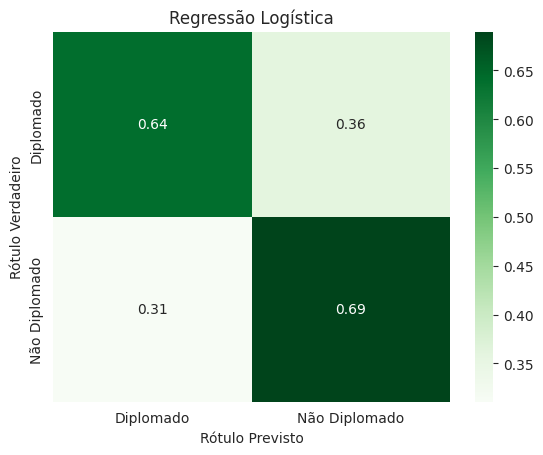

               precision    recall  f1-score   support

    Diplomado       0.60      0.64      0.62       486
Não Diplomado       0.72      0.69      0.71       663

     accuracy                           0.67      1149
    macro avg       0.66      0.66      0.66      1149
 weighted avg       0.67      0.67      0.67      1149



,Train Accuracy,Test Accuracy,Test f1
Regressão Logística,0.68,0.67,0.66


In [ ]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=250)

log_reg.fit(X_res, y_res)
ypred_log_reg = log_reg.predict(Xtest_scl)

acc_train_log_reg = log_reg.score(X_res, y_res)

model_evaluation(acc_train_log_reg, ytest_enc, ypred_log_reg, "Regressão Logística")


# 7. k Vizinhos Mais Próximos (kNN)


## 7.1 Modelo Base


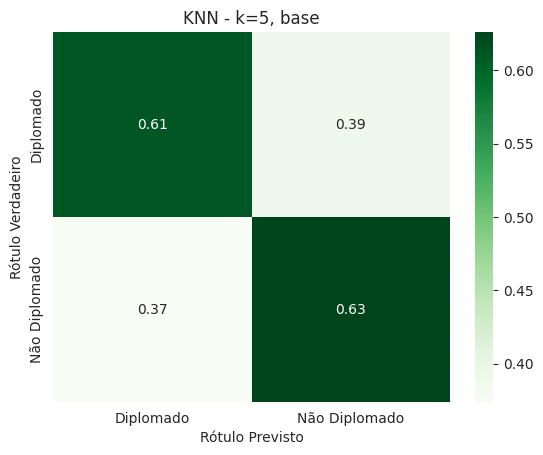

               precision    recall  f1-score   support

    Diplomado       0.54      0.61      0.58       486
Não Diplomado       0.69      0.63      0.66       663

     accuracy                           0.62      1149
    macro avg       0.62      0.62      0.62      1149
 weighted avg       0.63      0.62      0.62      1149



,Train Accuracy,Test Accuracy,Test f1
Regressão Logística,0.68,0.67,0.66
"KNN - k=5, base",0.77,0.62,0.62


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
# 5 vizinhos mais próximos
knn = KNeighborsClassifier()
knn.fit(X_res, y_res)
ypred_knn = knn.predict(Xtest_scl)

acc_train_knn = knn.score(X_res, y_res)
model_evaluation(acc_train_knn, ytest_enc, ypred_knn, "KNN - k=5, base")


## 7.2 Otimização de Parâmetros com GridSearchCV


In [ ]:
param_grid_knn = {
    "n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "metric": ["euclidean", "manhattan"]
}

gs_knn = GridSearchCV(KNeighborsClassifier(), param_grid_knn,
                      cv=5, scoring="accuracy")
gs_knn.fit(X_res, y_res)

print("Melhores parâmetros:", gs_knn.best_params_)
print(f"Melhor f1_macro (CV): {gs_knn.best_score_:.3f}")


Melhores parâmetros: {'metric': 'manhattan', 'n_neighbors': 11}
Melhor f1_macro (CV): 0.666


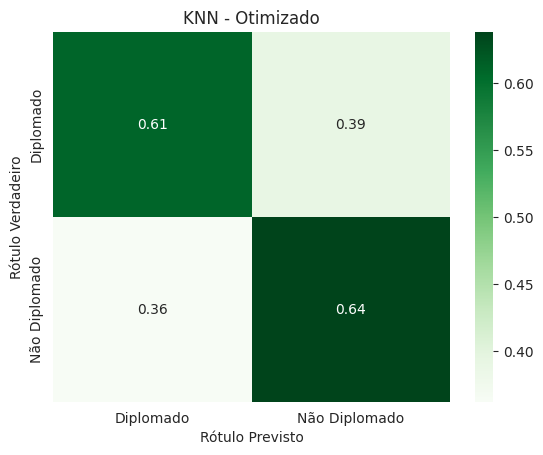

               precision    recall  f1-score   support

    Diplomado       0.55      0.61      0.58       486
Não Diplomado       0.69      0.64      0.66       663

     accuracy                           0.63      1149
    macro avg       0.62      0.62      0.62      1149
 weighted avg       0.63      0.63      0.63      1149



,Train Accuracy,Test Accuracy,Test f1
Regressão Logística,0.68,0.67,0.66
"KNN - k=5, base",0.77,0.62,0.62
KNN - Otimizado,0.73,0.63,0.62


In [ ]:
knn_opt = gs_knn.best_estimator_
ypred_knn_opt = knn_opt.predict(Xtest_scl)
acc_train_knn_opt = knn_opt.score(X_res, y_res)
model_evaluation(acc_train_knn_opt, ytest_enc, ypred_knn_opt, "KNN - Otimizado")


# 8. Máquinas de Vetor de Suporte (SVM)


## 8.1 Modelo Base (kernel RBF)


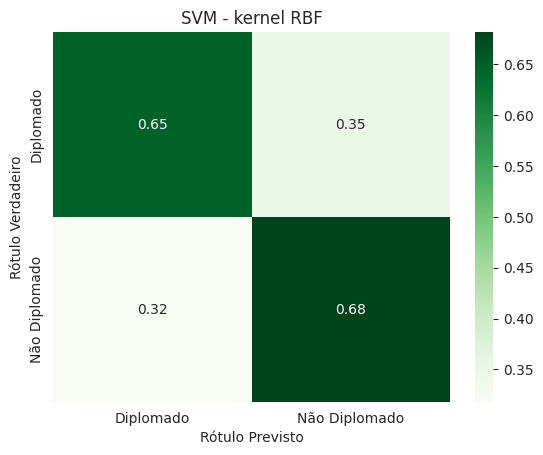

               precision    recall  f1-score   support

    Diplomado       0.60      0.65      0.62       486
Não Diplomado       0.73      0.68      0.70       663

     accuracy                           0.67      1149
    macro avg       0.66      0.66      0.66      1149
 weighted avg       0.67      0.67      0.67      1149



,Train Accuracy,Test Accuracy,Test f1
Regressão Logística,0.68,0.67,0.66
"KNN - k=5, base",0.77,0.62,0.62
KNN - Otimizado,0.73,0.63,0.62
SVM - kernel RBF,0.68,0.67,0.66


In [ ]:
from sklearn.svm import SVC

svm = SVC(kernel="rbf")
svm.fit(X_res, y_res)

ypred_svm = svm.predict(Xtest_scl)
acc_train_svm = svm.score(X_res, y_res)

model_evaluation(acc_train_svm, ytest_enc, ypred_svm, "SVM - kernel RBF")


## 8.2 Otimização com GridSearchCV


In [ ]:
parametros  = {
    "C": [0.1, 1, 2, 5],
    "gamma": ["scale", "auto", 1, 2],
    "kernel": ["rbf", "linear"]
}

gs_svm = GridSearchCV(SVC(), parametros ,refit=True, verbose=2)
gs_svm.fit(X_res, y_res)




Fitting 5 folds for each of 32 candidates, totalling 160 fits
[CV] END .....................C=0.1, gamma=scale, kernel=rbf; total time=   0.9s
[CV] END .....................C=0.1, gamma=scale, kernel=rbf; total time=   0.9s
[CV] END .....................C=0.1, gamma=scale, kernel=rbf; total time=   1.5s
[CV] END .....................C=0.1, gamma=scale, kernel=rbf; total time=   1.6s
[CV] END .....................C=0.1, gamma=scale, kernel=rbf; total time=   1.0s
[CV] END ..................C=0.1, gamma=scale, kernel=linear; total time=   0.6s
[CV] END ..................C=0.1, gamma=scale, kernel=linear; total time=   0.6s
[CV] END ..................C=0.1, gamma=scale, kernel=linear; total time=   0.6s
[CV] END ..................C=0.1, gamma=scale, kernel=linear; total time=   0.6s
[CV] END ..................C=0.1, gamma=scale, kernel=linear; total time=   0.6s
[CV] END ......................C=0.1, gamma=auto, kernel=rbf; total time=   0.9s
[CV] END ......................C=0.1, gamma=aut

GridSearchCV(estimator=SVC(),
             param_grid={'C': [0.1, 1, 2, 5], 'gamma': ['scale', 'auto', 1, 2],
                         'kernel': ['rbf', 'linear']},
             verbose=2)

In [ ]:
print("Melhores parâmetros:", gs_svm.best_params_)
print(f"Melhor exatidão obtida: {gs_svm.best_score_:.3f}")
gs_svm.best_estimator_

Melhores parâmetros: {'C': 1, 'gamma': 2, 'kernel': 'rbf'}
Melhor exatidão obtida: 0.687


SVC(C=1, gamma=2)

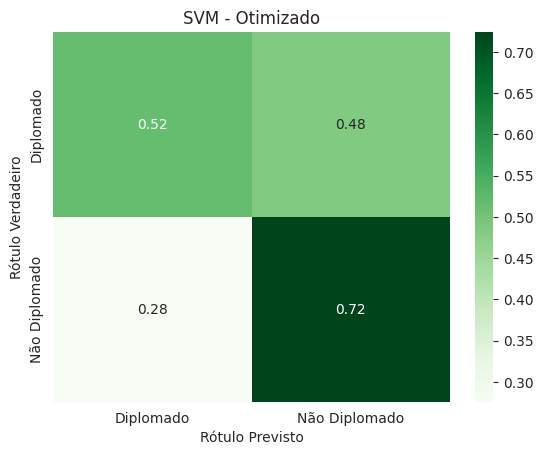

               precision    recall  f1-score   support

    Diplomado       0.58      0.52      0.55       486
Não Diplomado       0.67      0.72      0.70       663

     accuracy                           0.64      1149
    macro avg       0.62      0.62      0.62      1149
 weighted avg       0.63      0.64      0.63      1149



,Train Accuracy,Test Accuracy,Test f1
Regressão Logística,0.68,0.67,0.66
"KNN - k=5, base",0.77,0.62,0.62
KNN - Otimizado,0.73,0.63,0.62
SVM - kernel RBF,0.68,0.67,0.66
SVM - Otimizado,0.90,0.64,0.62


In [ ]:
svm_opt = gs_svm.best_estimator_
ypred_svm_opt = svm_opt.predict(Xtest_scl)
acc_train_svm_opt = svm_opt.score(X_res, y_res)
model_evaluation(acc_train_svm_opt, ytest_enc, ypred_svm_opt, "SVM - Otimizado")


# 9. Árvore de Decisão

## 9.1 Modelo Base


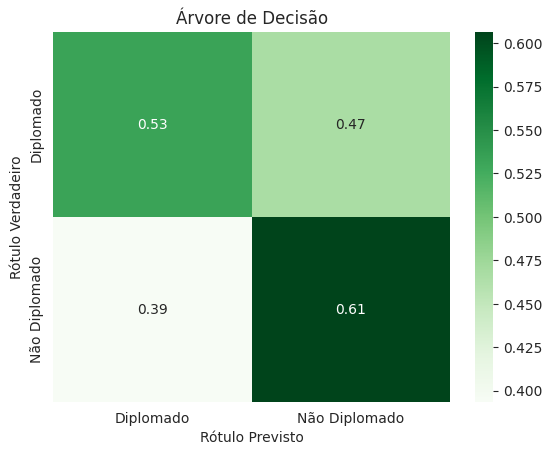

               precision    recall  f1-score   support

    Diplomado       0.50      0.53      0.51       486
Não Diplomado       0.64      0.61      0.62       663

     accuracy                           0.58      1149
    macro avg       0.57      0.57      0.57      1149
 weighted avg       0.58      0.58      0.58      1149



,Train Accuracy,Test Accuracy,Test f1
Regressão Logística,0.68,0.67,0.66
"KNN - k=5, base",0.77,0.62,0.62
KNN - Otimizado,0.73,0.63,0.62
SVM - kernel RBF,0.68,0.67,0.66
SVM - Otimizado,0.90,0.64,0.62
Árvore de Decisão,1.00,0.58,0.57


In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

arvore = DecisionTreeClassifier()
arvore.fit(X_res, y_res)

ypred_arvore = arvore.predict(Xtest_scl)
acc_train_arvore = arvore.score(X_res, y_res)

model_evaluation(acc_train_arvore, ytest_enc, ypred_arvore, "Árvore de Decisão")


Há uma enorme diferença entre a exatidão de treino e de teste, o que indica que o modelo está em overfitting.

In [ ]:
arvore.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': None,
 'splitter': 'best'}

## 9.2 Otimização com GridSearchCV


In [ ]:
param_grid_dt = {
    "max_depth": [ 5, 10, 15, None],        # valores a testar para profundidade máxima
    "min_samples_leaf": [2, 5, 10],         # valores para mín. de amostras numa folha
    "max_leaf_nodes": [None, 2, 5, 10, 20], # nr máx. de nodes
    "min_samples_split" : [2,5, 10, 20]     # nr mín de amostras para gerar node
}

gs_dt = GridSearchCV(DecisionTreeClassifier(),
                     param_grid_dt,
                     cv=5,
                     scoring="accuracy")
gs_dt.fit(X_res, y_res)


GridSearchCV(cv=5, estimator=DecisionTreeClassifier(),
             param_grid={'max_depth': [5, 10, 15, None],
                         'max_leaf_nodes': [None, 2, 5, 10, 20],
                         'min_samples_leaf': [2, 5, 10],
                         'min_samples_split': [2, 5, 10, 20]},
             scoring='accuracy')

In [ ]:
print("Melhores parâmetros:", gs_dt.best_params_)
print("Exatidao do melhor modelo: %.f" %gs_dt.best_score_)
gs_dt.best_estimator_

Melhores parâmetros: {'max_depth': 5, 'max_leaf_nodes': 5, 'min_samples_leaf': 2, 'min_samples_split': 2}
Exatidao do melhor modelo: 1


DecisionTreeClassifier(max_depth=5, max_leaf_nodes=5, min_samples_leaf=2)

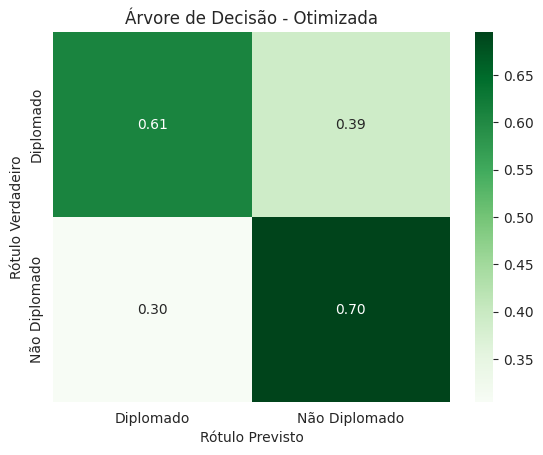

               precision    recall  f1-score   support

    Diplomado       0.59      0.61      0.60       486
Não Diplomado       0.71      0.70      0.70       663

     accuracy                           0.66      1149
    macro avg       0.65      0.65      0.65      1149
 weighted avg       0.66      0.66      0.66      1149



,Train Accuracy,Test Accuracy,Test f1
Regressão Logística,0.68,0.67,0.66
"KNN - k=5, base",0.77,0.62,0.62
KNN - Otimizado,0.73,0.63,0.62
SVM - kernel RBF,0.68,0.67,0.66
SVM - Otimizado,0.90,0.64,0.62
Árvore de Decisão,1.00,0.58,0.57
Árvore de Decisão - Otimizada,0.69,0.66,0.65


In [ ]:
arvore_opt = gs_dt.best_estimator_
ypred_arvore_opt = arvore_opt.predict(Xtest_scl)
acc_train_arvore_opt = arvore_opt.score(X_res, y_res)

model_evaluation(acc_train_arvore_opt, ytest_enc, ypred_arvore_opt, "Árvore de Decisão - Otimizada")


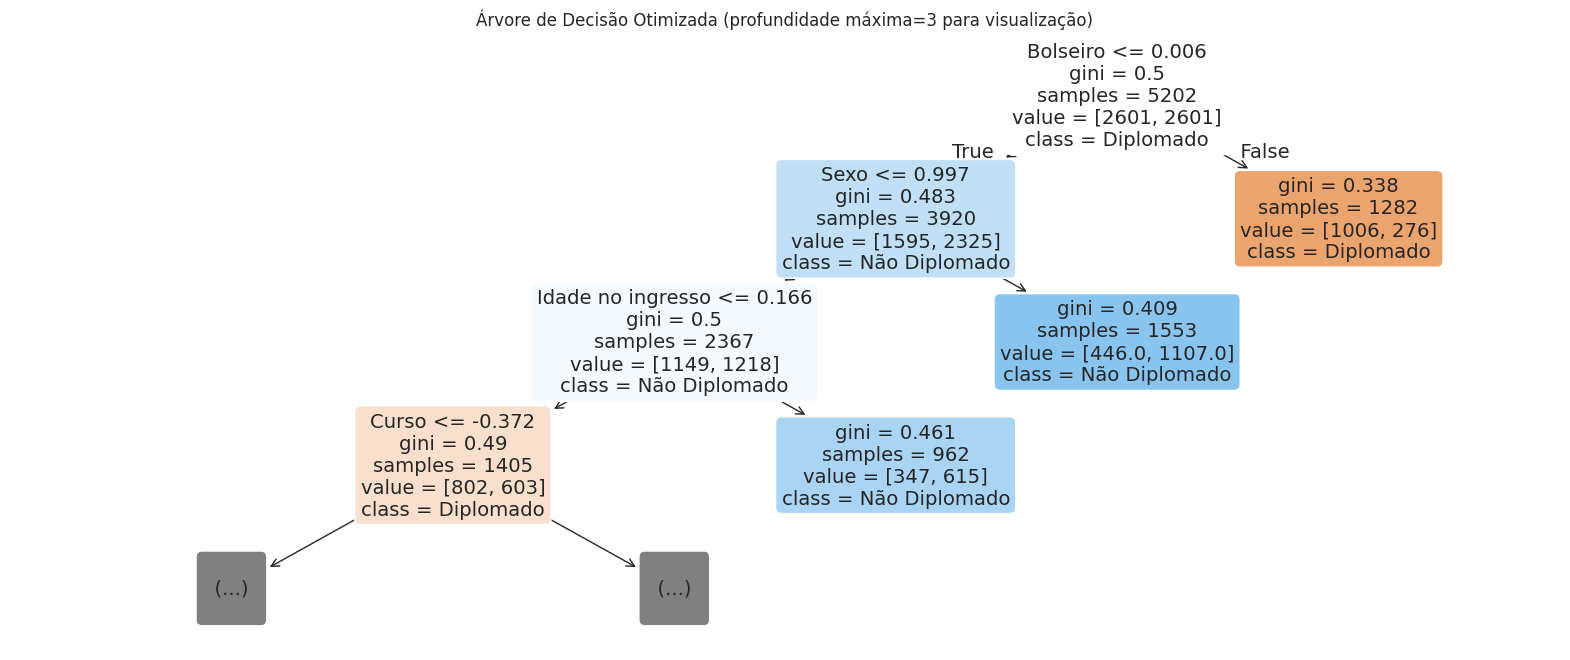

In [ ]:
# Visualizar a árvore otimizada
plt.figure(figsize=(20, 8))
plot_tree(arvore_opt, feature_names=Xtrain_encoded.columns, class_names=rotulos,
          filled=True, rounded=True, max_depth=3)
plt.title("Árvore de Decisão Otimizada (profundidade máxima=3 para visualização)")
plt.show()


# 10. Floresta Aleatória (Random Forest)


## 10.1 Modelo Base


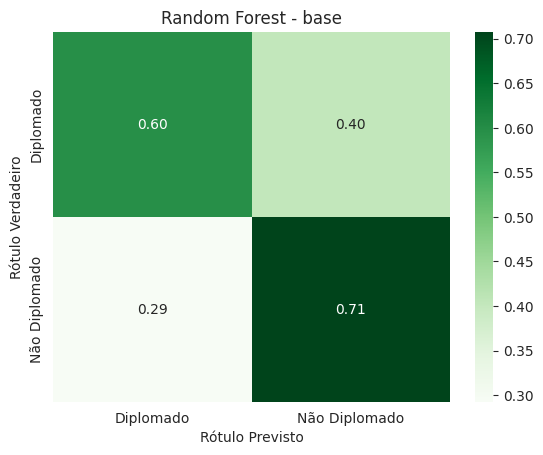

               precision    recall  f1-score   support

    Diplomado       0.60      0.60      0.60       486
Não Diplomado       0.71      0.71      0.71       663

     accuracy                           0.66      1149
    macro avg       0.65      0.65      0.65      1149
 weighted avg       0.66      0.66      0.66      1149



,Train Accuracy,Test Accuracy,Test f1
Regressão Logística,0.68,0.67,0.66
"KNN - k=5, base",0.77,0.62,0.62
KNN - Otimizado,0.73,0.63,0.62
SVM - kernel RBF,0.68,0.67,0.66
SVM - Otimizado,0.90,0.64,0.62
Árvore de Decisão,1.00,0.58,0.57
Árvore de Decisão - Otimizada,0.69,0.66,0.65
Random Forest - base,1.00,0.66,0.65


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100)
rf.fit(X_res, y_res)

ypred_rf = rf.predict(Xtest_scl)
acc_train_rf = rf.score(X_res, y_res)

model_evaluation(acc_train_rf, ytest_enc, ypred_rf, "Random Forest - base")


## 10.2 Otimização com GridSearchCV


In [ ]:
param_grid_rf = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 5, 10, 15],
    "min_samples_leaf": [1, 2, 4],
    "min_samples_split": [2, 5, 10],
    "max_features": ['sqrt', 'log2', None],
}

gs_rf = GridSearchCV(RandomForestClassifier(),
                     param_grid_rf,
                     cv=5,
                     scoring="accuracy",
                     verbose=1,
                     n_jobs=-1)

gs_rf.fit(X_res, y_res)

print("Exatidão do melhor modelo: %.2f" % gs_rf.best_score_)
print("Melhores parâmetros:", gs_rf.best_params_)


Fitting 5 folds for each of 324 candidates, totalling 1620 fits
Exatidão do melhor modelo: 0.71
Melhores parâmetros: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


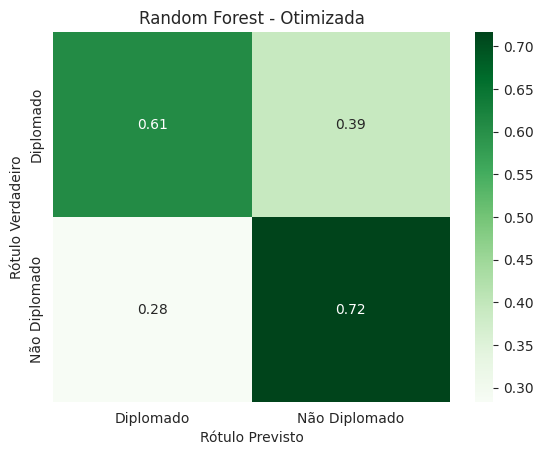

               precision    recall  f1-score   support

    Diplomado       0.61      0.61      0.61       486
Não Diplomado       0.71      0.72      0.71       663

     accuracy                           0.67      1149
    macro avg       0.66      0.66      0.66      1149
 weighted avg       0.67      0.67      0.67      1149



,Train Accuracy,Test Accuracy,Test f1
Regressão Logística,0.68,0.67,0.66
"KNN - k=5, base",0.77,0.62,0.62
KNN - Otimizado,0.73,0.63,0.62
SVM - kernel RBF,0.68,0.67,0.66
SVM - Otimizado,0.90,0.64,0.62
Árvore de Decisão,1.00,0.58,0.57
Árvore de Decisão - Otimizada,0.69,0.66,0.65
Random Forest - base,1.00,0.66,0.65
Random Forest - Otimizada,0.96,0.67,0.66


In [ ]:
rf_opt = gs_rf.best_estimator_
ypred_rf_opt = rf_opt.predict(Xtest_scl)
acc_train_rf_opt = rf_opt.score(X_res, y_res)
model_evaluation(acc_train_rf_opt, ytest_enc, ypred_rf_opt, "Random Forest - Otimizada")


# 11. Rede Neuronal

In [ ]:
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense, Input
from keras.callbacks import EarlyStopping
from keras import metrics


In [ ]:
def definir_modelo(units=[8]):
    modelo = Sequential()
    modelo.add(Input(shape=(X_res.shape[1],))) # camada de entrada
    modelo.add(Dense(units[0], activation = 'relu'))  #primeira camada interna
    for u in units[1:]: # camadas internas seguintes
        modelo.add(Dense(u, activation = 'relu'))
    modelo.add(Dense(1, activation = 'sigmoid')) # camada de saída
    print(modelo.summary())
    modelo.compile(optimizer = 'adam', loss='binary_crossentropy', metrics=['accuracy'])
    return modelo

In [ ]:
#treinar modelo com callback e validação
def treinar_modelo(modelo, Xtrain=X_res, ytrain=y_res, epocas=140, batch = 16 ):
  early_stop = EarlyStopping(monitor = 'val_loss',  # métrica que vai ser monitorizada
                            patience = 10,  # número de épocas sem melhoria antes de parar
                            restore_best_weights = True # volta ao melhor modelo (não ao último)
                            )
  return modelo.fit(Xtrain, ytrain,
                    batch_size=batch,
                    validation_split = 0.2, epochs=epocas,
                    callbacks=early_stop, verbose=0)

In [ ]:
def visualizar(nome,treino):
    #exatidão
    plt.title(nome)
    plt.subplot(1,2,1)
    plt.plot(treino.history['accuracy'], label='Treino')
    plt.plot(treino.history['val_accuracy'], label='Validação')
    plt.ylabel('Exatidão')
    plt.xlabel('Época')
    #custo
    plt.subplot(1,2,2)
    plt.plot(treino.history['loss'], label = "Treino")
    plt.plot(treino.history['val_loss'], label = "Validação")
    plt.ylabel('Custo')
    plt.xlabel('Época')

   # plt.tight_layout()
    plt.show()

In [ ]:
# avaliar
def avaliar_modelo(modelo, treino, Xtest = Xtest_scl, ytest = ytest_enc, nome_modelo=" " ):
    acc_train=treino.history['accuracy'][-1]
    ypred=(modelo.predict(Xtest))
    ypred=(ypred>0.5).astype('int64')
    ytest=ytest.astype('int64')
    model_evaluation(acc_train, ytest, ypred, nome_modelo)

In [ ]:
def  modelo_nn(nome, units=[8]):
  modelo = definir_modelo(units=units)
  treino = treinar_modelo(modelo)
  visualizar(nome, treino)
  avaliar_modelo(modelo, treino, Xtest_scl, ytest_enc, nome)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 5)              │            65 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71 (284.00 B)

 Trainable params: 71 (284.00 B)

 Non-trainable params: 0 (0.00 B)

None


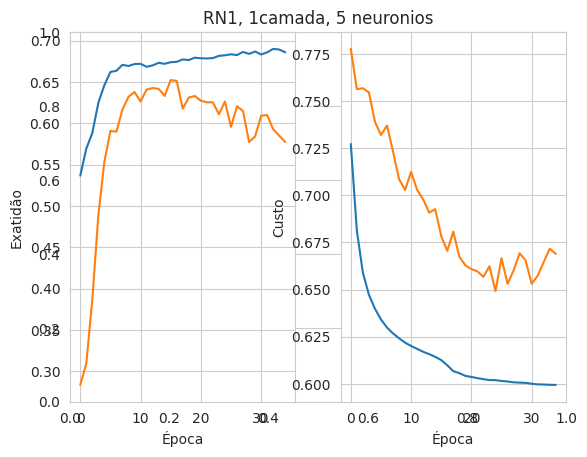

36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


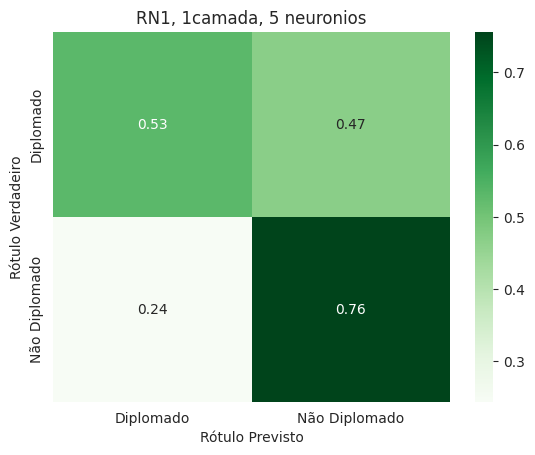

               precision    recall  f1-score   support

    Diplomado       0.61      0.53      0.57       486
Não Diplomado       0.69      0.76      0.72       663

     accuracy                           0.66      1149
    macro avg       0.65      0.64      0.64      1149
 weighted avg       0.66      0.66      0.66      1149



,Train Accuracy,Test Accuracy,Test f1
Regressão Logística,0.68,0.67,0.66
"KNN - k=5, base",0.77,0.62,0.62
KNN - Otimizado,0.73,0.63,0.62
SVM - kernel RBF,0.68,0.67,0.66
SVM - Otimizado,0.90,0.64,0.62
Árvore de Decisão,1.00,0.58,0.57
Árvore de Decisão - Otimizada,0.69,0.66,0.65
Random Forest - base,1.00,0.66,0.65
Random Forest - Otimizada,0.96,0.67,0.66
"RN1, 1camada, 5 neuronios",0.69,0.66,0.64


In [ ]:
modelo_nn("RN1, 1camada, 5 neuronios",[5])


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 113 (452.00 B)

 Trainable params: 113 (452.00 B)

 Non-trainable params: 0 (0.00 B)

None


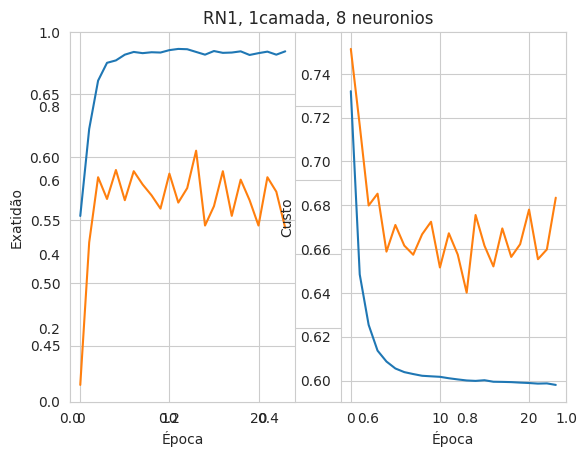

36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


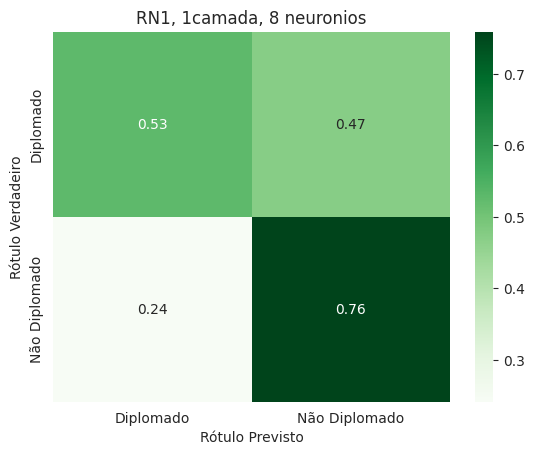

               precision    recall  f1-score   support

    Diplomado       0.62      0.53      0.57       486
Não Diplomado       0.69      0.76      0.72       663

     accuracy                           0.66      1149
    macro avg       0.65      0.64      0.64      1149
 weighted avg       0.66      0.66      0.66      1149



,Train Accuracy,Test Accuracy,Test f1
Regressão Logística,0.68,0.67,0.66
"KNN - k=5, base",0.77,0.62,0.62
KNN - Otimizado,0.73,0.63,0.62
SVM - kernel RBF,0.68,0.67,0.66
SVM - Otimizado,0.90,0.64,0.62
Árvore de Decisão,1.00,0.58,0.57
Árvore de Decisão - Otimizada,0.69,0.66,0.65
Random Forest - base,1.00,0.66,0.65
Random Forest - Otimizada,0.96,0.67,0.66
"RN1, 1camada, 5 neuronios",0.69,0.66,0.64


In [ ]:
modelo_nn("RN1, 1camada, 8 neuronios",[8])

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 16)             │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 353 (1.38 KB)

 Trainable params: 353 (1.38 KB)

 Non-trainable params: 0 (0.00 B)

None


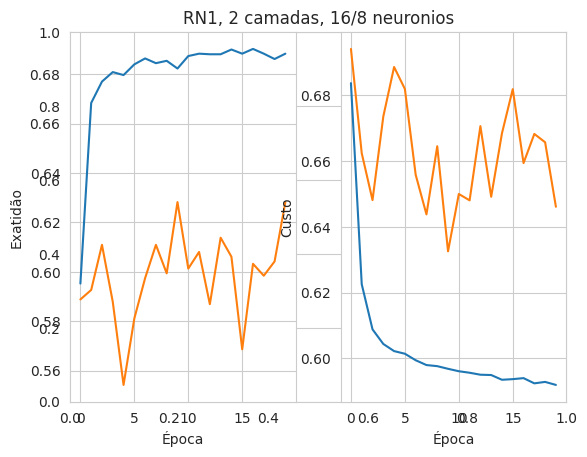

36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


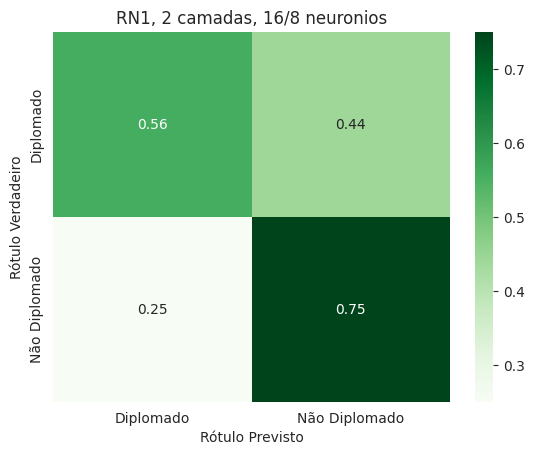

               precision    recall  f1-score   support

    Diplomado       0.62      0.56      0.59       486
Não Diplomado       0.70      0.75      0.72       663

     accuracy                           0.67      1149
    macro avg       0.66      0.65      0.66      1149
 weighted avg       0.67      0.67      0.67      1149



,Train Accuracy,Test Accuracy,Test f1
Regressão Logística,0.68,0.67,0.66
"KNN - k=5, base",0.77,0.62,0.62
KNN - Otimizado,0.73,0.63,0.62
SVM - kernel RBF,0.68,0.67,0.66
SVM - Otimizado,0.90,0.64,0.62
Árvore de Decisão,1.00,0.58,0.57
Árvore de Decisão - Otimizada,0.69,0.66,0.65
Random Forest - base,1.00,0.66,0.65
Random Forest - Otimizada,0.96,0.67,0.66
"RN1, 1camada, 5 neuronios",0.69,0.66,0.64


In [ ]:
modelo_nn("RN1, 2 camadas, 16/8 neuronios",[16,8])

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 32)             │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,089 (4.25 KB)

 Trainable params: 1,089 (4.25 KB)

 Non-trainable params: 0 (0.00 B)

None


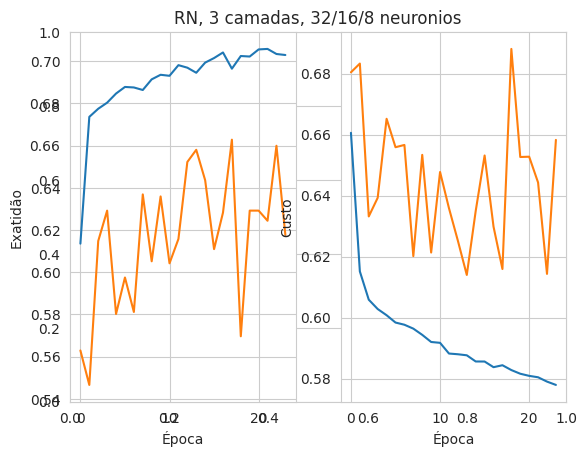

36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


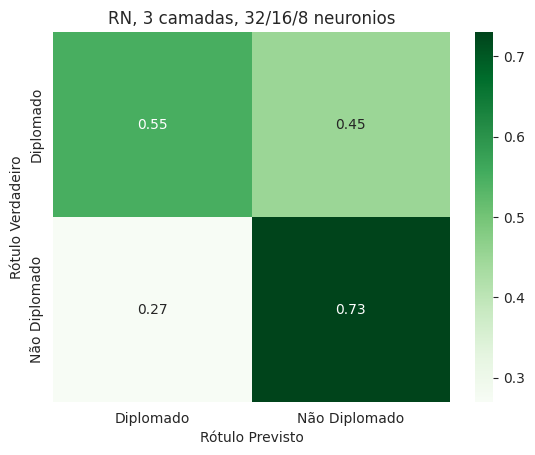

               precision    recall  f1-score   support

    Diplomado       0.60      0.55      0.57       486
Não Diplomado       0.69      0.73      0.71       663

     accuracy                           0.65      1149
    macro avg       0.64      0.64      0.64      1149
 weighted avg       0.65      0.65      0.65      1149



,Train Accuracy,Test Accuracy,Test f1
Regressão Logística,0.68,0.67,0.66
"KNN - k=5, base",0.77,0.62,0.62
KNN - Otimizado,0.73,0.63,0.62
SVM - kernel RBF,0.68,0.67,0.66
SVM - Otimizado,0.90,0.64,0.62
Árvore de Decisão,1.00,0.58,0.57
Árvore de Decisão - Otimizada,0.69,0.66,0.65
Random Forest - base,1.00,0.66,0.65
Random Forest - Otimizada,0.96,0.67,0.66
"RN1, 1camada, 5 neuronios",0.69,0.66,0.64


In [ ]:
modelo_nn("RN, 3 camadas, 32/16/8 neuronios",[32,16,8])

# 12. Importância das Características

A análise de importância das características permite perceber quais os atributos mais relevantes para a previsão. Usa-se a Floresta Aleatória otimizada, que disponibiliza diretamente .


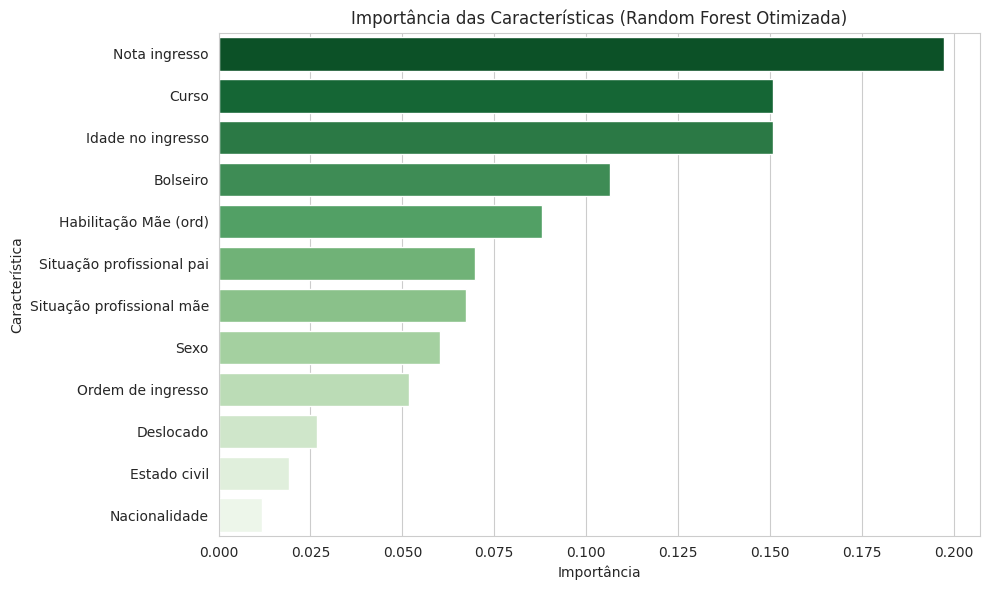

Nota ingresso                0.197282
Curso                        0.150806
Idade no ingresso            0.150743
Bolseiro                     0.106548
Habilitação Mãe (ord)        0.087938
Situação profissional pai    0.069707
Situação profissional mãe    0.067361
Sexo                         0.060266
Ordem de ingresso            0.051683
Deslocado                    0.026790
Estado civil                 0.019082
Nacionalidade                0.011794


In [ ]:
importances = rf_opt.feature_importances_
feat_imp = pd.Series(importances, index=X_res.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=feat_imp.values, y=feat_imp.index, palette="Greens_r")
plt.title("Importância das Características (Random Forest Otimizada)")
plt.xlabel("Importância")
plt.ylabel("Característica")
plt.tight_layout()
plt.show()

print(feat_imp.to_string())


# 13. Comparação dos Modelos


In [ ]:
display(performance.sort_values(by='Test f1', ascending=False))

,Train Accuracy,Test Accuracy,Test f1
Regressão Logística,0.68,0.67,0.66
SVM - kernel RBF,0.68,0.67,0.66
Random Forest - Otimizada,0.96,0.67,0.66
"RN1, 2 camadas, 16/8 neuronios",0.69,0.67,0.66
Árvore de Decisão - Otimizada,0.69,0.66,0.65
Random Forest - base,1.00,0.66,0.65
"RN1, 1camada, 5 neuronios",0.69,0.66,0.64
"RN1, 1camada, 8 neuronios",0.68,0.66,0.64
"RN, 3 camadas, 32/16/8 neuronios",0.70,0.65,0.64
"KNN - k=5, base",0.77,0.62,0.62


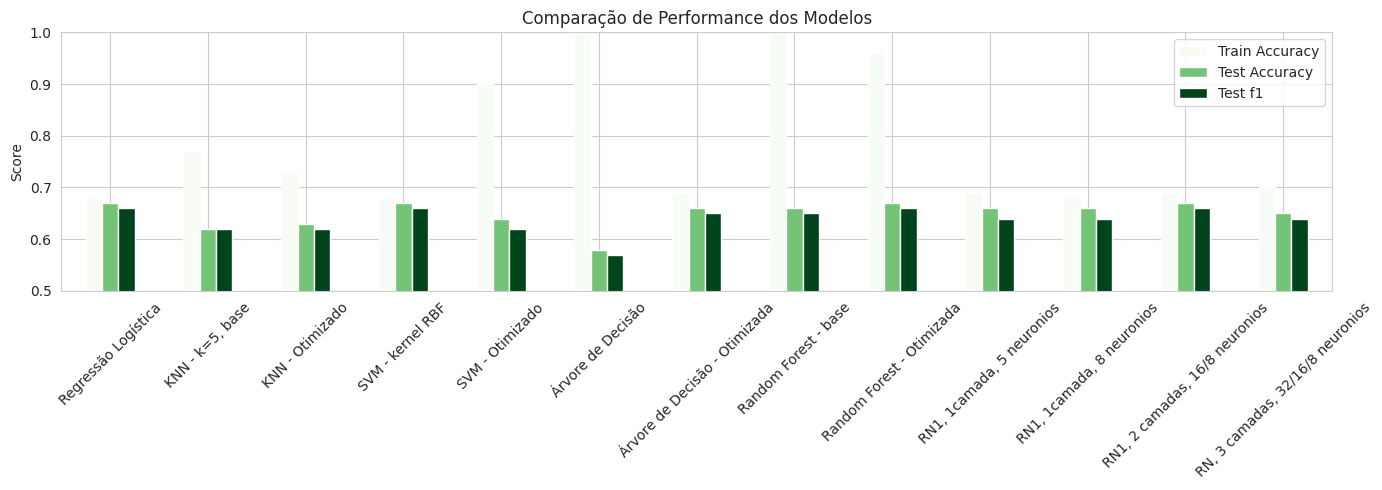

In [ ]:
# Visualização comparativa
perf_plot = performance.astype(float)
perf_plot[["Train Accuracy", "Test Accuracy", "Test f1"]].plot(
    kind="bar", figsize=(14, 5), colormap="Greens", rot=45, ylim=(0.5, 1.0)
)
plt.title("Comparação de Performance dos Modelos")
plt.ylabel("Score")
plt.tight_layout()
plt.show()


# 14. Conclusões

### Pré-processamento
O pipeline de pré-processamento foi construído com especial atenção à prevenção de data leakage, garantindo que todas as transformações foram ajustadas (fit) exclusivamente nos dados de treino e apenas aplicadas (transform) aos dados de teste.

Os principais passos foram:
* imputação de valores ausentes com mediana (variáveis numéricas) e valor mais frequente (variáveis categóricas);
* codificação de variáveis binárias com OneHotEncoder(drop='first');
* codificação ordinal da habilitação literária da mãe, mapeada para uma escala de anos de escolaridade equivalentes;
* codificação das restantes variáveis categóricas com OrdinalEncoder, com tratamento explícito de categorias não observadas no treino;
* e padronização das variáveis contínuas e ordinais com RobustScaler, selecionado pela sua robustez à presença de outliers.

Para mitigar o desequilíbrio entre classes (43% Diplomados / 57% Não Diplomados), aplicou-se SMOTE exclusivamente ao conjunto de treino, gerando exemplos sintéticos da classe minoritária sem introduzir informação do conjunto de teste.


### Análise de Importância de Características
**Nota de ingresso:**

É o preditor mais forte. Uma nota de ingresso mais elevada está associada a maior probabilidade de diplomação, o que é consistente com a literatura sobre desempenho académico: alunos com melhor preparação prévia têm maior taxa de conclusão.

**Curso:**

É o segundo fator mais relevante. Isto reflete diferenças estruturais entre cursos, seja na sua exigência, nas saídas profissionais que motivam os alunos, ou na duração, o que influencia diretamente a variável alvo.


**Idade no ingresso**

A idade é um preditor significativo. Estudantes mais velhos no momento do ingresso tendem a ter perfis de vida distintos (compromissos profissionais ou familiares), o que pode dificultar a conclusão em N anos.


**Bolseiro**

Ser ou não bolseiro revela-se um fator de peso considerável. Pode refletir tanto o estatuto socioeconómico do estudante como a pressão adicional de manutenção da bolsa condicionada ao aproveitamento académico, o que poderá ter efeitos opostos consoante os casos.


**Habilitação Mãe (ord)**

Embora em 5.º lugar, o nível de escolaridade da mãe é um conhecido preditor socioeconómico do sucesso académico.


###  Modelo Eleito
A Random Forest Otimizada é o modelo mais indicado por três razões:
* como método de ensemble baseado em múltiplas árvores de decisão, é naturalmente mais robusto ao overfitting do que uma árvore individual;
* disponibiliza diretamente a importância das características, permitindo interpretabilidade;
* os métodos de ensemble tendem a superar modelos lineares (Regressão Logística) e baseados em distância (kNN) em dados tabulares com variáveis mistas.

Modelos alternativos como a Regressão Logística e o SVM RBF (sem otimização) atingiram métricas idênticas de accuracy e F1, podendo ser considerados complementares.